# Generative Adversarial Network Example

Build a generative adversarial network (GAN) to generate digit images from
a noise distribution with JAX.

This example is using a low-level approach: the generator and discriminator
are plain Python functions, their weights are stored in dictionaries of
arrays, and the gradients are computed with `jax.grad`.

- Author: Aymeric Damien
- Project: [https://github.com/aymericdamien/JAX-Examples/](https://github.com/aymericdamien/JAX-Examples/)

## GAN Overview

<img src="http://www.timzhangyuxuan.com/static/images/project_DCGAN/structure.png" alt="nn" style="width: 800px;"/>

References:
- [Generative adversarial nets](https://arxiv.org/pdf/1406.2661.pdf). I Goodfellow, J Pouget-Abadie, M Mirza, B Xu, D Warde-Farley, S Ozair, Y. Bengio. Advances in neural information processing systems, 2672-2680.
- [Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification](https://arxiv.org/abs/1502.01852). K He, X Zhang, S Ren, J Sun. ICCV 2015.

Other tutorials:
- [Generative Adversarial Networks Explained](http://kvfrans.com/generative-adversial-networks-explained/). Kevin Frans.

## MNIST Dataset Overview

This example is using MNIST handwritten digits. The dataset contains 60,000 examples for training and 10,000 examples for testing. The digits have been size-normalized and centered in a fixed-size image (28x28 pixels) with values from 0 to 255.

In this example, each image will be converted to float32, normalized to [0, 1] and flattened to a 1-D array of 784 features (28*28).

![MNIST Dataset](http://neuralnetworksanddeeplearning.com/images/mnist_100_digits.png)

More info: http://yann.lecun.com/exdb/mnist/

In [1]:
import os
import sys

import jax
import jax.numpy as jnp
import numpy as np
import optax

# Make the shared helpers of the 'common' folder importable.
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from common.datasets import load_mnist, batch_iterator

In [2]:
# MNIST Dataset parameters.
image_dim = 784  # 28*28 pixels.

# Training parameters.
learning_rate = 0.0002
training_steps = 20000
batch_size = 128
display_step = 2000

# Network parameters.
gen_hidden_dim = 256
disc_hidden_dim = 256
noise_dim = 100  # Noise data points.

In [3]:
# Prepare MNIST data.
(x_train, y_train), (x_test, y_test) = load_mnist()
# Convert to float32.
x_train, x_test = np.array(x_train, np.float32), np.array(x_test, np.float32)
# Flatten images to 1-D vector of 784 features (28*28).
x_train, x_test = x_train.reshape([-1, image_dim]), x_test.reshape([-1, image_dim])
# Normalize images value from [0, 255] to [0, 1].
x_train, x_test = x_train / 255., x_test / 255.

# Shuffle and batch data (a simple data loader, see 'common/datasets.py').
train_data = batch_iterator(x_train, y_train, batch_size)

In [4]:
# Store layers weight & bias.

# Random values are generated from a random 'key', which is split to get a
# new key for every use.
keys = jax.random.split(jax.random.key(0), 4)

# A custom initialization (see Kaiming He init): random values with a
# standard deviation of sqrt(2 / fan_in).
def he_init(key, shape):
    return jax.random.normal(key, shape) / jnp.sqrt(shape[0] / 2.)

# The two networks are trained separately (each with its own optimizer),
# so we store their parameters in two separate dictionaries.
gen_params = {
    'weights': {
        'gen_hidden1': he_init(keys[0], [noise_dim, gen_hidden_dim]),
        'gen_out': he_init(keys[1], [gen_hidden_dim, image_dim]),
    },
    'biases': {
        'gen_hidden1': jnp.zeros([gen_hidden_dim]),
        'gen_out': jnp.zeros([image_dim]),
    },
}
disc_params = {
    'weights': {
        'disc_hidden1': he_init(keys[2], [image_dim, disc_hidden_dim]),
        'disc_out': he_init(keys[3], [disc_hidden_dim, 1]),
    },
    'biases': {
        'disc_hidden1': jnp.zeros([disc_hidden_dim]),
        'disc_out': jnp.zeros([1]),
    },
}

In [5]:
# Generator.
# Input: noise, Output: an image (784 pixels with values in [0, 1]).
def generator(gen_params, x):
    weights, biases = gen_params['weights'], gen_params['biases']
    hidden_layer = jnp.matmul(x, weights['gen_hidden1'])
    hidden_layer = jnp.add(hidden_layer, biases['gen_hidden1'])
    hidden_layer = jax.nn.relu(hidden_layer)
    out_layer = jnp.matmul(hidden_layer, weights['gen_out'])
    out_layer = jnp.add(out_layer, biases['gen_out'])
    out_layer = jax.nn.sigmoid(out_layer)
    return out_layer


# Discriminator.
# Input: an image, Output: the probability that this image is a real one.
def discriminator(disc_params, x):
    weights, biases = disc_params['weights'], disc_params['biases']
    hidden_layer = jnp.matmul(x, weights['disc_hidden1'])
    hidden_layer = jnp.add(hidden_layer, biases['disc_hidden1'])
    hidden_layer = jax.nn.relu(hidden_layer)
    out_layer = jnp.matmul(hidden_layer, weights['disc_out'])
    out_layer = jnp.add(out_layer, biases['disc_out'])
    out_layer = jax.nn.sigmoid(out_layer)
    return out_layer

# Losses. A tiny value (1e-10) is added inside the logs, to keep them finite
# when the discriminator output reaches exactly 0 or 1.
# The generator tries to make the discriminator classify fake images as real.
def generator_loss(gen_params, disc_params, noise):
    disc_fake = discriminator(disc_params, generator(gen_params, noise))
    return -jnp.mean(jnp.log(disc_fake + 1e-10))

# The discriminator tries to classify real images as real, and fake as fake.
def discriminator_loss(disc_params, gen_params, real_images, noise):
    disc_real = discriminator(disc_params, real_images)
    disc_fake = discriminator(disc_params, generator(gen_params, noise))
    return -jnp.mean(jnp.log(disc_real + 1e-10) + jnp.log(1. - disc_fake + 1e-10))

# Optimizers (one for each network).
optimizer_gen = optax.adam(learning_rate)
optimizer_disc = optax.adam(learning_rate)
gen_opt_state = optimizer_gen.init(gen_params)
disc_opt_state = optimizer_disc.init(disc_params)

# Optimization process. Inputs: real images and noise.
# @jax.jit compiles the function with XLA, so it runs much faster
# (see '1_Introduction/transformations.py').
@jax.jit
def run_optimization(gen_params, disc_params, gen_opt_state, disc_opt_state,
                     real_images, noise):
    # Compute each loss and its gradients. 'jax.grad' differentiates with
    # respect to the first argument only: the generator loss is differentiated
    # with respect to the generator parameters, and the discriminator loss
    # with respect to the discriminator parameters.
    gen_loss, gradients_gen = jax.value_and_grad(generator_loss)(
        gen_params, disc_params, noise)
    disc_loss, gradients_disc = jax.value_and_grad(discriminator_loss)(
        disc_params, gen_params, real_images, noise)

    # Update each network with its own optimizer.
    updates, gen_opt_state = optimizer_gen.update(gradients_gen, gen_opt_state)
    gen_params = optax.apply_updates(gen_params, updates)
    updates, disc_opt_state = optimizer_disc.update(gradients_disc, disc_opt_state)
    disc_params = optax.apply_updates(disc_params, updates)

    # JAX arrays can't be modified in place: return the updated values.
    return gen_params, disc_params, gen_opt_state, disc_opt_state, gen_loss, disc_loss

In [6]:
# Run training for the given number of steps.
key = jax.random.key(1)
for step in range(1, training_steps + 1):
    # Get the next batch of data (only the images are needed, not the labels).
    batch_x, _ = next(train_data)
    # Generate noise to feed to the generator (with a new random key).
    key, noise_key = jax.random.split(key)
    noise = jax.random.uniform(noise_key, [batch_size, noise_dim], minval=-1., maxval=1.)
    # Run the optimization.
    gen_params, disc_params, gen_opt_state, disc_opt_state, gen_loss, disc_loss = \
        run_optimization(gen_params, disc_params, gen_opt_state, disc_opt_state,
                         batch_x, noise)

    if step % display_step == 0 or step == 1:
        print("step: %i, gen_loss: %f, disc_loss: %f" % (step, gen_loss, disc_loss))

step: 1, gen_loss: 1.183844, disc_loss: 1.306554


step: 2000, gen_loss: 4.607469, disc_loss: 0.058882


step: 4000, gen_loss: 4.417164, disc_loss: 0.070514


step: 6000, gen_loss: 3.345766, disc_loss: 0.171591


step: 8000, gen_loss: 4.208853, disc_loss: 0.192105


step: 10000, gen_loss: 3.569687, disc_loss: 0.246386


step: 12000, gen_loss: 3.171136, disc_loss: 0.295484


step: 14000, gen_loss: 3.989612, disc_loss: 0.184632


step: 16000, gen_loss: 4.005210, disc_loss: 0.289372


step: 18000, gen_loss: 4.230354, disc_loss: 0.118119


step: 20000, gen_loss: 4.117485, disc_loss: 0.210803


In [7]:
# Visualize predictions.
import matplotlib.pyplot as plt

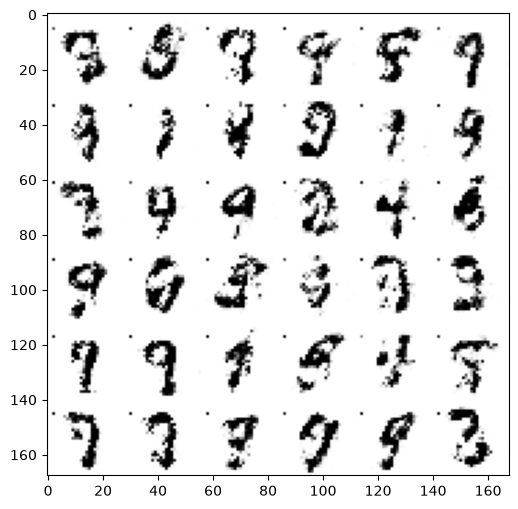

In [8]:
# Testing
# Generate images from noise, using the generator network.
n = 6
canvas = np.empty((28 * n, 28 * n))
for i in range(n):
    # Noise input.
    key, noise_key = jax.random.split(key)
    z = jax.random.uniform(noise_key, [n, noise_dim], minval=-1., maxval=1.)
    # Generate image from noise.
    g = np.asarray(generator(gen_params, z))
    # Reverse colours for better display
    g = -1 * (g - 1)
    for j in range(n):
        # Draw the generated digits
        canvas[i * 28:(i + 1) * 28, j * 28:(j + 1) * 28] = g[j].reshape([28, 28])

plt.figure(figsize=(n, n))
plt.imshow(canvas, origin="upper", cmap="gray")
plt.show()

With 20000 training steps, many generated digits still look alike: the
generator found a few digits that fool the discriminator, and produces them
again and again (a common GAN problem, called 'mode collapse'). Train
longer (e.g. 100000 steps) to get better and more varied digits.